# TP1 — Contagem e Classificação de Peças de Lego Retangulares

Pipeline de segmentação e extração de propriedades, desenvolvido a partir da imagem `lego01.jpg` e validado nas 14 imagens de treino.

In [217]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Leitura da imagem e espaços de cor
Lê-se a imagem de exemplo e convertem-se para cinzentos, RGB e HSV.

In [218]:
caminho_exemplo = os.path.join("./treino", "lego01.jpg")

img = cv2.imread(caminho_exemplo)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

h, s, v = cv2.split(img_hsv)

## 2. Histogramas de H e S

A mesa ocupa a maior parte da imagem, por isso o pico de cada histograma corresponde à cor da mesa.

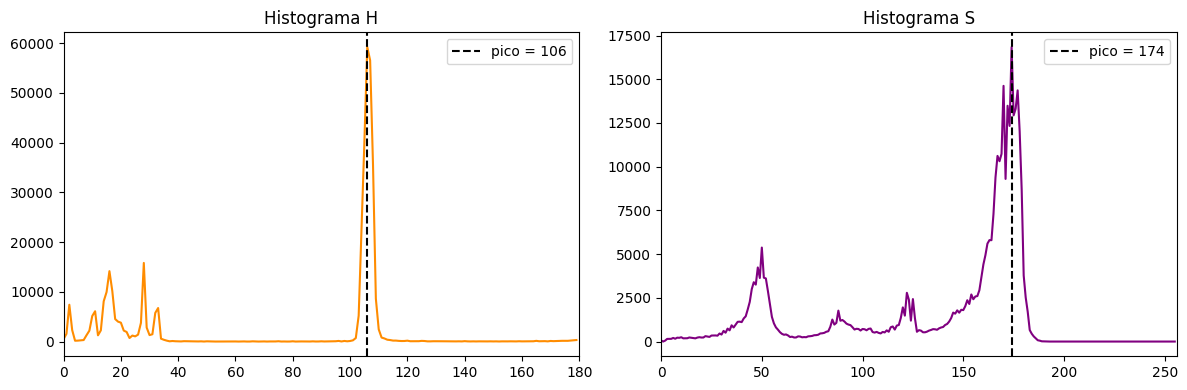

Pico H: 106 | Pico S: 174


In [219]:
histH = cv2.calcHist([h], [0], None, [180], [0, 180])
histS = cv2.calcHist([s], [0], None, [256], [0, 256])

maxH = np.argmax(histH)
maxS = np.argmax(histS)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(histH, color="darkorange")
axs[0].axvline(maxH, color="black", linestyle="--", label=f"pico = {maxH}")
axs[0].set_title("Histograma H")
axs[0].set_xlim([0, 180])
axs[0].legend()

axs[1].plot(histS, color="purple")
axs[1].axvline(maxS, color="black", linestyle="--", label=f"pico = {maxS}")
axs[1].set_title("Histograma S")
axs[1].set_xlim([0, 256])
axs[1].legend()

plt.tight_layout()
plt.show()

print("Pico H:", maxH, "| Pico S:", maxS)

## 3. Segmentação por cor da mesa (HSV + inRange)

Define-se um intervalo [pico - margem, pico + margem] em H e S à volta da cor da mesa. A máscara da mesa é invertida para ter a máscara das peças, e limpa-se com morfologia (open + close).

In [ ]:
margem_h = 60
margem_s = 60

h_min, h_max = np.clip(maxH - margem_h, 0, 179), np.clip(maxH + margem_h, 0, 179)
s_min, s_max = np.clip(maxS - margem_s, 0, 255), np.clip(maxS + margem_s, 0, 255)

minimo = np.array([h_min, s_min, 0], dtype=np.uint8)
maximo = np.array([h_max, s_max, 255], dtype=np.uint8)

mascara_mesa = cv2.inRange(img_hsv, minimo, maximo)
mascara_peca = cv2.bitwise_not(mascara_mesa)

closed = cv2.morphologyEx(mascara_peca, cv2.MORPH_CLOSE, kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
eroded = cv2.erode(closed, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)), iterations=4)
dilated = cv2.dilate(eroded, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15,15)), iterations=3)


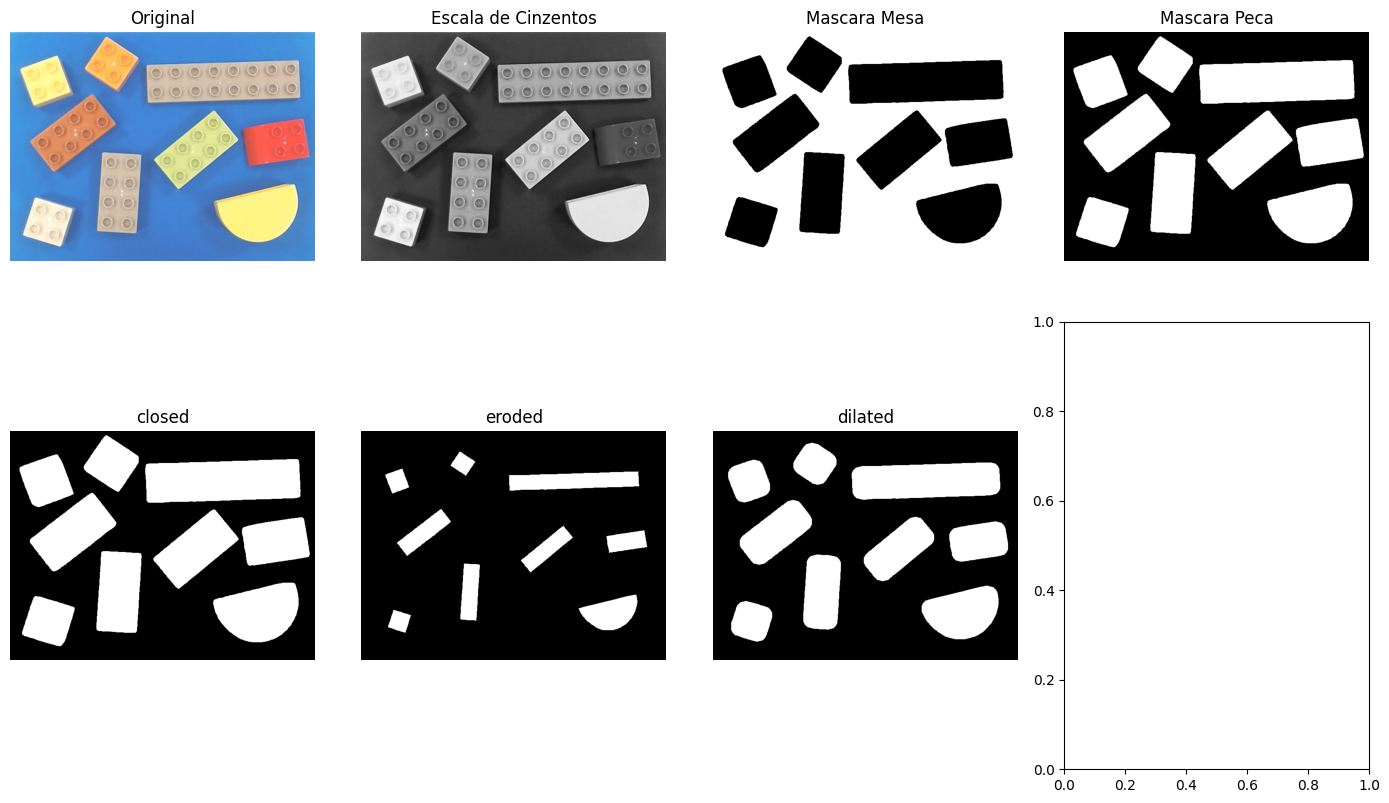

In [221]:
imagens = [img_rgb, img_gray, mascara_mesa, mascara_peca, closed, eroded, dilated]
titulos = ["Original", "Escala de Cinzentos", "Mascara Mesa", "Mascara Peca", "closed", "eroded", "dilated"]

fig, axs = plt.subplots(2, 4, figsize=(14, 9))
for ax, imagem, titulo in zip(axs.flat, imagens, titulos):
    ax.imshow(imagem, cmap="gray")
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Contornos e propriedades de forma

Numero de contornos encontrados: 9


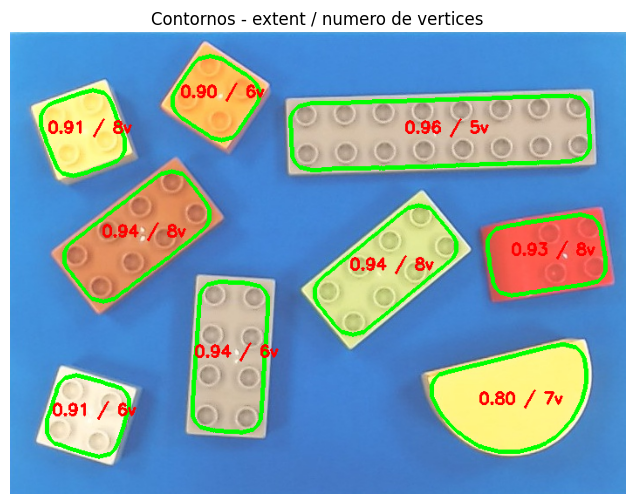

Peca 0: extent=0.909, vertices=6
Peca 1: extent=0.796, vertices=7
Peca 2: extent=0.945, vertices=6
Peca 3: extent=0.933, vertices=8
Peca 4: extent=0.945, vertices=8
Peca 5: extent=0.940, vertices=8
Peca 6: extent=0.960, vertices=5
Peca 7: extent=0.906, vertices=8
Peca 8: extent=0.904, vertices=6


In [222]:
contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
print("Numero de contornos encontrados:", len(contours))

contornos_img = img_rgb.copy()
cv2.drawContours(contornos_img, contours, -1, (0, 255, 0), 3)

resultados_exemplo = []
for c in contours:
    (centro, (largura, altura), _) = cv2.minAreaRect(c)
    area_retangulo = largura * altura
    if area_retangulo == 0:
        continue
    extent = cv2.contourArea(c) / area_retangulo

    epsilon = 0.02 * cv2.arcLength(c, True)
    num_vertices = len(cv2.approxPolyDP(c, epsilon, True))

    resultados_exemplo.append((extent, num_vertices))

    x, y = int(centro[0]), int(centro[1])
    texto = f"{extent:.2f} / {num_vertices}v"
    cv2.putText(contornos_img, texto, (x - 40, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.figure(figsize=(8, 6))
plt.imshow(contornos_img)
plt.title("Contornos - extent / numero de vertices")
plt.axis("off")
plt.show()

for i, (extent, nv) in enumerate(resultados_exemplo):
    print(f"Peca {i}: extent={extent:.3f}, vertices={nv}")